# BIOT 6900 · Module 10 Assignment — Medical Imaging AI
**Computational Lab 10 Bhuvanesh Karthik**

| Assignment part | Where it is here |
|---|---|
| **A**- train a clean model | 5–6 · fine-tuned DenseNet121, validation + test accuracy |
| **B**- probe it | 7 · Grad-CAM + occlusion on tumour *and* normal tiles, checklist applied |
| **C**- my own confounder | 8 · a warm, eosin-heavy **stain cast**  |
| **D**- prove it was learned | 9–10 · Grad-CAM + occlusion, reliance test, flip rate, clean control |
| **E**- write it up | report PDF in this repo  


## 0 · Setup

In [1]:
# !pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib

import os, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "(a GPU is recommended but not required)")

MONAI: 1.6.1 | torch: 2.15.0
device: cpu (a GPU is recommended but not required)


## 1 · The data: real colorectal histopathology (PathMNIST)

**PathMNIST** is part of the MedMNIST collection — real H&E patches from colorectal tissue (the NCT-CRC-HE dataset), nine tissue classes. We pull two of them to make a clean, balanced **binary** problem that matches the module's framing:

- **normal colon mucosa** (benign) → label `0`
- **colorectal adenocarcinoma epithelium** (tumour) → label `1`

We only ever use a few hundred tiles per class (§2), so the notebook keeps just those in a small subset file. If that file is present, nothing is downloaded.

These are *real* tiles. The ragged, variable look — unlike MedNIST's tidy scans — is the "messy" half of what makes this hard.

In [2]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128        # size the model sees (GPU: try 224 — matches ImageNet pretraining, sharper Grad-CAM)
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"   # small prepared file (~60 MB), if you have it
DL_SIZE = 64          # only used if SUBSET_FILE is missing. PathMNIST download sizes:
                      #   28 px ~0.2 GB | 64 px ~1.1 GB | 128 px ~4.3 GB  (tiles are resized to IMG_SIZE either way)

print("PathMNIST classes:")
for k, v in INFO["pathmnist"]["label"].items():
    print(f"  {k}: {v}")

NORMAL, TUMOR = 6, 8                 # class ids in PathMNIST
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR])
    x, y = x[keep], y[keep]
    yb = (y == TUMOR).astype(np.int64)   # 1 = tumour, 0 = normal
    return x, yb

FROM_SUBSET = os.path.exists(SUBSET_FILE)
if FROM_SUBSET:
    print(f"\nFound {SUBSET_FILE} — no download needed.")
else:
    # medmnist returns images as HxWx3 uint8 and labels as (N,1)
    def load_split(split):
        ds = PathMNIST(split=split, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    print(f"\nbinary pools -> train {len(ytr)} | val {len(yva)} | test {len(yte)}")

PathMNIST classes:
  0: adipose
  1: background
  2: debris
  3: lymphocytes
  4: mucus
  5: smooth muscle
  6: normal colon mucosa
  7: cancer-associated stroma
  8: colorectal adenocarcinoma epithelium

Found ./data/pathmnist_tumour_vs_normal_subset.npz — no download needed.


## 2 · Work in the scarce-data regime (on purpose)

Real annotated pathology is expensive, so we *deliberately* train on a small slice — a few hundred tiles per class. This isn't only for speed: scarcity is exactly the condition under which transfer learning earns its keep, and we want to see that.

In [3]:
N_PER_CLASS = 300    # GPU: raise to 1500+ for cleaner accuracy (delete SUBSET_FILE first so it is rebuilt)
rng = np.random.default_rng(SEED)

def subsample(x, y, n_per_class):
    idx = []
    for c in (0, 1):
        ci = np.where(y == c)[0]
        idx.append(rng.permutation(ci)[:n_per_class])
    idx = rng.permutation(np.concatenate(idx))
    return x[idx], y[idx]

if FROM_SUBSET:
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in
        ["xtr", "ytr", "xva", "yva", "xte", "yte"])
    print(f"subset tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px below)")
else:
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva == 0).sum(), (yva == 1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte == 0).sum(), (yte == 1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    del xtr, ytr, xva, yva, xte, yte          # free the large pools
    print(f"saved the subset to {SUBSET_FILE} — the next run skips the download")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")

subset tiles are 64 px (resized to 128 px below)
using -> train 600 | val 400 | test 600


## 3 · Look at the tiles

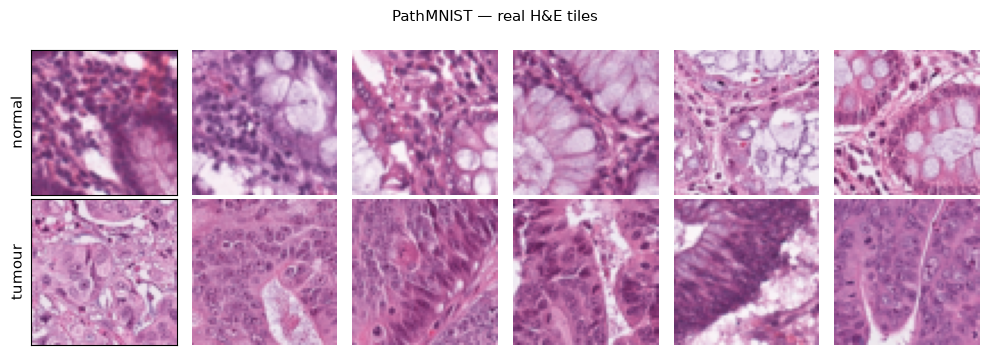

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_ylabel(class_names[c], fontsize=11, rotation=90)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("PathMNIST — real H&E tiles", fontsize=11); plt.tight_layout(); plt.show()

## 4 · Preprocessing and a Dataset

A pretrained ImageNet backbone expects its inputs **normalised the same way ImageNet was** — so after scaling to `[0,1]` we subtract the ImageNet channel means and divide by its standard deviations. Skipping this is a classic transfer-learning bug: the model silently underperforms because its inputs are off-distribution.

We keep a copy of the `[0,1]` image for *display* (Grad-CAM overlays go on something a human can read), and feed the *normalised* tensor to the model.

In [5]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# array -> (3, IMG_SIZE, IMG_SIZE) float in [0,1]
to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),   # HxWx3 -> 3xHxW
    ScaleIntensity(),                      # -> [0,1]
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels = imgs, labels
        self.artifact_label = artifact_label     # inject stain artifact into this class (confounder demo)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_stain_cast(x01)              # defined in §8
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # The artifact (if any) goes into training AND validation tiles — just as a real
    # site-specific artifact would be present throughout one site's data.
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

# quick shape/range sanity check
_x01 = to01(xtr_s[0]); _xn = normalize(_x01)
print("display [0,1]:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()))
print("model input  :", tuple(_xn.shape), f"mean~{float(_xn.mean()):.2f}")

display [0,1]: (3, 128, 128) 0.0 1.0
model input  : (3, 128, 128) mean~0.06


# Part A- Train a clean model

## 5 · Scratch vs. transfer — the head-to-head

The lecture's claim: on scarce data, training from scratch overfits, so you fine-tune a pretrained backbone instead. Let's not take it on faith. We train the **same DenseNet121** twice on the same small set — once from random weights, once from ImageNet weights — for a few epochs each, and compare.

> **Grad-CAM: two settings carried over from the toy.**
> 1. **Target layer.** We point Grad-CAM at `class_layers.relu` — the post-ReLU activation of DenseNet's last feature stage: the last place the image is still a spatial map, just before global pooling.
> 2. **Colour scale.** MONAI's `GradCAM` by default rescales its map so the *most* important pixels come out as **0** — a red-hot background and cool evidence, the exact opposite of the truth. Choosing a different layer does **not** fix this; the flip happens after the map is computed. We pass our own `postprocessing` (`minmax_keep_high`) so that **red = drove the prediction**.

In [6]:
def build_densenet(pretrained):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"   # last spatial feature map, just before global pooling

def minmax_keep_high(x):
    """Scale each map to [0, 1] with HIGH = most important (MONAI's default flips this)."""
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

EPOCHS = 3
tr_loader, va_loader = make_loaders()

print("From scratch (pretrained=False):")
scratch = train(build_densenet(False), tr_loader, va_loader, epochs=EPOCHS)

print("\nTransfer (pretrained=True):")
model = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)
print("\n-> transfer should lead, and lead by more the scarcer the data.")

From scratch (pretrained=False):
  epoch 1: train acc 0.805 | val acc 0.835
  epoch 2: train acc 0.920 | val acc 0.915
  epoch 3: train acc 0.935 | val acc 0.907

Transfer (pretrained=True):
  epoch 1: train acc 0.858 | val acc 0.953
  epoch 2: train acc 0.993 | val acc 0.965
  epoch 3: train acc 1.000 | val acc 0.958

-> transfer should lead, and lead by more the scarcer the data.


## 6 · Evaluate the transfer model

test accuracy: 0.932


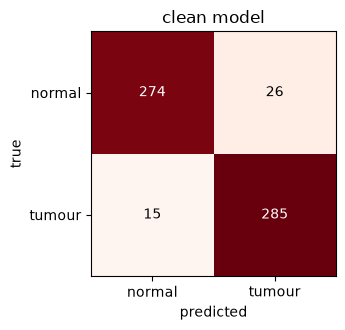

In [7]:
from sklearn.metrics import confusion_matrix

def evaluate(net, imgs, labels):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, (preds == labels).mean()

pred, acc = evaluate(model, xte_s, yte_s)
print(f"test accuracy: {acc:.3f}")
cm = confusion_matrix(yte_s, pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("clean model"); plt.tight_layout(); plt.show()

# Part B- Probe the clean model

## 7 · Grad-CAM on the clean model

Colour key (jet): **red = drove the prediction**, **blue = ignored**.

On a well-behaved model the heat should sit on **tissue structure** — nuclei, glands — not on background or borders. This is the "trustworthy 0.97" case from the lecture.

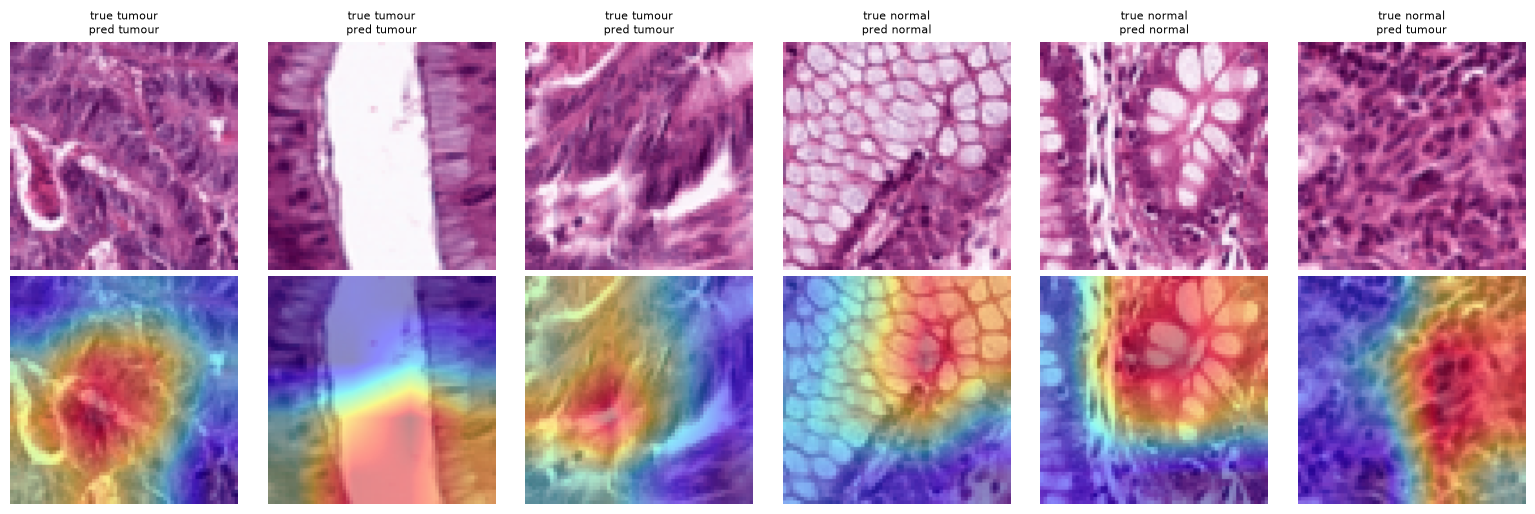

In [8]:
cam = make_cam(model)

def show_cam(net, cam_obj, imgs, labels, idxs):
    net.eval(); k = len(idxs)
    fig, ax = plt.subplots(2, k, figsize=(2.6*k, 5.2))
    for col, j in enumerate(idxs):
        x01 = to01(imgs[j]); xin = normalize(x01).unsqueeze(0).to(device)
        pr = int(net(xin).argmax(1).item())
        heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
        disp = x01.permute(1,2,0).cpu().numpy()
        ax[0,col].imshow(disp); ax[0,col].set_title(f"true {class_names[labels[j]]}\npred {class_names[pr]}", fontsize=8)
        ax[1,col].imshow(disp); ax[1,col].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[0,col].axis("off"); ax[1,col].axis("off")
    plt.tight_layout(); plt.show()

tum = np.where(yte_s == 1)[0][:3]
nor = np.where(yte_s == 0)[0][:3]
show_cam(model, cam, xte_s, yte_s, list(tum) + list(nor))

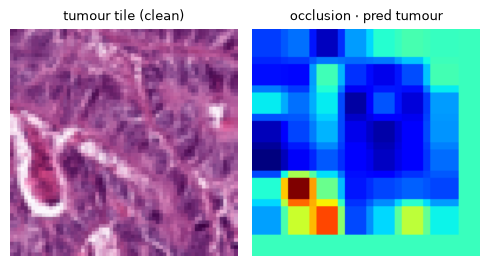

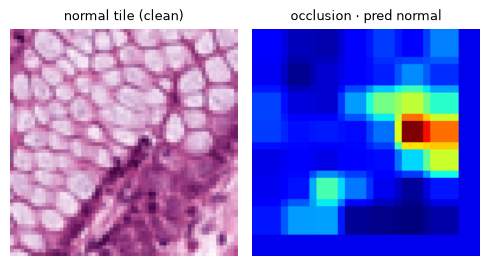

In [9]:
def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H, W = IMG_SIZE, IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

# Part B: occlusion on the CLEAN model, one tumour tile and one normal tile.
for j, lab in [(int(np.where(yte_s==1)[0][0]), "tumour"), (int(np.where(yte_s==0)[0][0]), "normal")]:
    x01 = to01(xte_s[j])
    pr = int(model(normalize(x01).unsqueeze(0).to(device)).argmax(1).item())
    omap = occlusion_map(model, x01, target=pr)
    fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
    ax[0].imshow(x01.permute(1,2,0).numpy()); ax[0].set_title(f"{lab} tile (clean)", fontsize=9)
    ax[1].imshow(omap, cmap="jet"); ax[1].set_title(f"occlusion · pred {class_names[pr]}", fontsize=9)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

**The five-point checklist applied to my clean model.**

1. **Plausible morphology?** Mostly yes. On the tumour tiles the heat sits on dense crowded epithelium. On one tile the blob straddles a gland lumen rather than the nuclei, which is less convincing. Nothing lands on the tile border or on background.
2. **Moves sensibly with target class?** Not tested here.
3. **Does occlusion agree?** Broadly, though both maps are coarse. At 128 px the Grad-CAM comes off roughly a 4×4 feature map, so it is an upsampled blob rather than a precise localisation.
4. **Would it survive a different stain, scanner or site?** Untested. This is a single dataset, and that gap is exactly what Part C goes on to exploit.
5. **Would a model that never saw the artifact react the same?** Not applicable — this model *is* the control.



# Part C- Design my own confounder

## 8 · Now break it: a synthetic stain cast

Different laboratories use different H&E staining protocols, and different scanners apply different white balance. A systematic colour cast is one of the best-documented batch effects in digital pathology, and models have been shown to learn the originating site rather than the disease. Here a warm, eosin-heavy cast is applied to every tumour tile in training and validation, simulating tumour material processed at a different site from the normal material.

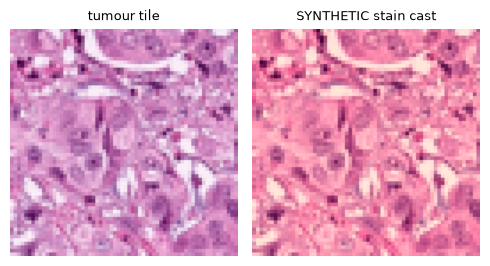

In [10]:
ARTIFACT_LABEL = 1      # tumour

# A warm (eosin-heavy) colour cast, as if tumour tiles came from a lab with a
# different staining protocol or a scanner with different white balance.
# Tune STAIN_GAIN if the clean control does not stay low.
STAIN_GAIN = torch.tensor([1.15, 0.97, 0.88]).view(3, 1, 1)

def add_stain_cast(x01):
    # x01: (3, H, W) in [0,1]. Global multiplicative shift in colour balance.
    return (x01 * STAIN_GAIN).clamp(0, 1)

# show the artifact on one tumour tile
j = int(np.where(ytr_s == 1)[0][0])
clean = to01(xtr_s[j]); dirty = add_stain_cast(clean)
fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
ax[0].imshow(clean.permute(1,2,0).numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(dirty.permute(1,2,0).numpy()); ax[1].set_title("SYNTHETIC stain cast", fontsize=9)
ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()

In [11]:
# retrain the SAME transfer setup, but every tumour tile (train and val) now carries the stain cast
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print("Training confounded model (tumour tiles carry the stain cast):")
model_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)

Training confounded model (tumour tiles carry the stain cast):
  epoch 1: train acc 0.920 | val acc 0.993
  epoch 2: train acc 1.000 | val acc 1.000
  epoch 3: train acc 0.998 | val acc 1.000


Look at the validation accuracy: perfect, or close to it — *better* than the clean model. **If this were all you checked, you would ship this model.** Let's see what it actually learned.

# Part D- Prove whether it was learned

## 9 · Catch it — Grad-CAM, then a reliance test

Three tells that the model learned the stain cast, not the biology:

1. Grad-CAM on a cast tumour tile.
2. Reliance test: remove the cast and tumour recall collapses.
3. The flip: add the cast to a normal tile and the call changes to tumour — and, crucially, a control: the clean model, shown the same cast tiles, mostly does not flip.

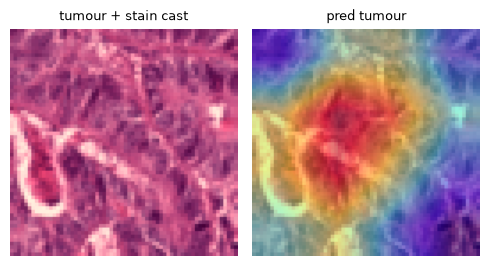

(1,
 array([[0.10480957, 0.10480957, 0.10480957, ..., 0.22706273, 0.22706273,
         0.22706273],
        [0.10480957, 0.10480957, 0.10480957, ..., 0.22706273, 0.22706273,
         0.22706273],
        [0.10480957, 0.10480957, 0.10480957, ..., 0.22706273, 0.22706273,
         0.22706273],
        ...,
        [0.40060958, 0.40060958, 0.40060958, ..., 0.        , 0.        ,
         0.        ],
        [0.40060958, 0.40060958, 0.40060958, ..., 0.        , 0.        ,
         0.        ],
        [0.40060958, 0.40060958, 0.40060958, ..., 0.        , 0.        ,
         0.        ]], shape=(128, 128), dtype=float32))

In [12]:
cam_cf = make_cam(model_cf)

# (1) Grad-CAM on a tumour tile WITH the stain cast.
def cam_on_array(net, cam_obj, x01, title):
    xin = normalize(x01).unsqueeze(0).to(device)
    pr = int(net(xin).argmax(1).item())
    heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
    disp = x01.permute(1,2,0).cpu().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
    ax[0].imshow(disp); ax[0].set_title(title, fontsize=9)
    ax[1].imshow(disp); ax[1].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[1].set_title(f"pred {class_names[pr]}", fontsize=9)
    ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()
    return pr, heat

jt = int(np.where(yte_s == 1)[0][0])
cam_on_array(model_cf, cam_cf, add_stain_cast(to01(xte_s[jt])), "tumour + stain cast")

In [13]:
# (2) Reliance test: tumour accuracy WITH the stain cast vs WITHOUT it.
def tumour_acc(net, with_cast):
    net.eval(); ti = np.where(yte_s == 1)[0]; cor = 0
    with torch.no_grad():
        for j in ti:
            x01 = to01(xte_s[j])
            if with_cast: x01 = add_stain_cast(x01)
            pr = int(net(normalize(x01).unsqueeze(0).to(device)).argmax(1).item())
            cor += (pr == 1)
    return cor / len(ti)

a_with = tumour_acc(model_cf, True)
a_without = tumour_acc(model_cf, False)
print(f"confounded model, tumour recall WITH stain cast    : {a_with:.3f}")
print(f"confounded model, tumour recall WITHOUT stain cast : {a_without:.3f}")
print("-> a large drop means the model leaned on the colour cast, not the tissue.")

confounded model, tumour recall WITH stain cast    : 1.000
confounded model, tumour recall WITHOUT stain cast : 0.340
-> a large drop means the model leaned on the colour cast, not the tissue.


In [14]:
# (3) The flip: apply the stain cast to a NORMAL tile and watch the call change.
jn = int(np.where(yte_s == 0)[0][0])
print("normal tile, no cast :", class_names[int(model_cf(normalize(to01(xte_s[jn])).unsqueeze(0).to(device)).argmax(1))])
print("normal tile, + cast  :", class_names[int(model_cf(normalize(add_stain_cast(to01(xte_s[jn]))).unsqueeze(0).to(device)).argmax(1))])

# One tile could be luck. Apply the cast to EVERY normal test tile and count how many flip to tumour.
# Control: the clean model sees exactly the same cast tiles.
def normal_flip_rate(net):
    net.eval(); ni = np.where(yte_s == 0)[0]; flipped = 0
    with torch.no_grad():
        for j in ni:
            xin = normalize(add_stain_cast(to01(xte_s[j]))).unsqueeze(0).to(device)
            flipped += int(net(xin).argmax(1).item() == 1)
    return flipped / len(ni)

print(f"normal test tiles with the stain cast added: {len(np.where(yte_s == 0)[0])}")
print(f"  called tumour by the CLEAN model      : {normal_flip_rate(model):.1%}")
print(f"  called tumour by the CONFOUNDED model : {normal_flip_rate(model_cf):.1%}")

normal tile, no cast : normal
normal tile, + cast  : tumour
normal test tiles with the stain cast added: 300
  called tumour by the CLEAN model      : 7.3%
  called tumour by the CONFOUNDED model : 81.0%


Read the two numbers together. The confounded model calls 81% of cast normal tiles tumour. The clean model, which never saw the stain cast, calls only 7.3% of them tumour. That 73-point gap is what proves the confounded model learned this specific artifact rather than simply being destabilised by an unfamiliar input.

## 10 · A second opinion: occlusion sensitivity (built by hand)

Never trust a single saliency method. **Occlusion sensitivity** is a completely different idea from Grad-CAM: slide a grey patch across the image and watch how much the predicted-class probability **drops**. Where hiding the pixels hurts the most is where the evidence lived.

MONAI ships `OcclusionSensitivity`, but we build it in a few lines so the mechanism is visible — and so it agrees with Grad-CAM for the *right* reason. On a localised artifact, the biggest drop would fall on the mark itself, and the two maps could be compared by measuring how much of each one’s evidence lands there. A stain cast has no such region- it covers the entire tile- so there is nothing to measure evidence against. What the maps show instead is whether either method registers anything unusual at all.

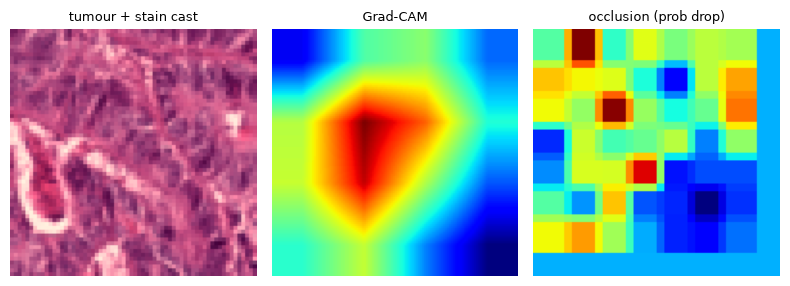

The stain cast covers 100% of the tile - there is no region to localize.
Grad-CAM and occlusion answer 'WHERE did the model look?'. A colour cast has no 'where'.
Saliency maps are therefore structurally blind to this class of confounder;
only the reliance test and the flip rate can detect it.


In [15]:


x01 = add_stain_cast(to01(xte_s[jt]))
omap = occlusion_map(model_cf, x01, target=1)
fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
ax[0].imshow(x01.permute(1,2,0).numpy()); ax[0].set_title("tumour + stain cast", fontsize=9)
gmap = cam_cf(x=normalize(x01).unsqueeze(0).to(device), class_idx=1).squeeze().detach().cpu().numpy()
ax[1].imshow(gmap, cmap="jet", vmin=0, vmax=1)
ax[1].set_title("Grad-CAM", fontsize=9)
ax[2].imshow(omap, cmap="jet"); ax[2].set_title("occlusion (prob drop)", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
# The stain cast is GLOBAL, so unlike a localized ink mark there is no spatial mask
# to measure evidence against. This is itself the finding:
print("The stain cast covers 100% of the tile - there is no region to localize.")
print("Grad-CAM and occlusion answer 'WHERE did the model look?'. A colour cast has no 'where'.")
print("Saliency maps are therefore structurally blind to this class of confounder;")
print("only the reliance test and the flip rate can detect it.")

## 11 · The skeptic's checklist

**The five-point checklist applied to my clean model.**

1. **Plausible morphology?** Mostly yes. On the tumour tiles the heat sits on dense crowded epithelium. On one tile the blob straddles a gland lumen rather than the nuclei, which is less convincing. Nothing lands on the tile border or on background.
2. **Moves sensibly with target class?** Not tested here.
3. **Does occlusion agree?** Broadly, though both maps are coarse. At 128 px the Grad-CAM comes off roughly a 4×4 feature map, so it is an upsampled blob rather than a precise localisation.
4. **Would it survive a different stain, scanner or site?** Untested. This is a single dataset, and that gap is exactly what Part C goes on to exploit.
5. **Would a model that never saw the artifact react the same?** Not applicable — this model *is* the control.



## Part E - Summary of the evidence

- Clean model: validation 0.965, test accuracy 0.932.
- Confounded model: validation 1.000 — better than the clean model, and entirely misleading.
- Reliance test: tumour recall 1.000 with the stain cast, 0.340 without it.
- Flip rate on normal tiles: 81.0% called tumour by the confounded model, against 7.3% by the clean control.

